In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

# Загрузка данных
df = pd.read_csv('creditcard.csv')

y = df['Class']
X = df.drop(columns=['Class'])

Note: you may need to restart the kernel to use updated packages.


In [4]:
# Сначала отделяем Test (20%)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Затем из оставшегося отделяем Val
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=42, stratify=y_train_full
)

# Сброс индексов
X_train = X_train.reset_index(drop=True)
X_val = X_val.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

print(f"Train: {X_train.shape}, фрод: {y_train.sum()}")
print(f"Val:   {X_val.shape}, фрод: {y_val.sum()}")
print(f"Test:  {X_test.shape}, фрод: {y_test.sum()}")

Train: (170883, 30), фрод: 295
Val:   (56962, 30), фрод: 99
Test:  (56962, 30), фрод: 98


In [7]:
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import average_precision_score
import pandas as pd

# 1. Считаем вес для компенсации дисбаланса
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_weight = neg_count / pos_count
print(f"Вес для компенсации дисбаланса (scale_pos_weight): {scale_weight:.2f}")

scores_xgb = []

# Задаем сетку параметров для перебора
# Обычно для XGBoost важно: глубина (max_depth), скорость обучения (learning_rate), количество деревьев (n_estimators)
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1, 0.2],
    'n_estimators': [50, 100, 200]
}

print("Запуск GridSearch для XGBoost (может занять пару минут)...")

for params in ParameterGrid(param_grid):
    xgb_model = xgb.XGBClassifier(
        **params, # Передаем текущие параметры из сетки
        scale_pos_weight=scale_weight,
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss'
    )
    
    # Обучаем на train
    xgb_model.fit(X_train, y_train)
    
    # Предсказания на val
    y_val_proba_xgb = xgb_model.predict_proba(X_val)[:, 1]
    
    # Считаем PR-AUC (главная метрика)
    pr_auc = average_precision_score(y_val, y_val_proba_xgb)
    
    # Сохраняем результаты
    scores_xgb.append({
        'max_depth': params['max_depth'],
        'learning_rate': params['learning_rate'],
        'n_estimators': params['n_estimators'],
        'pr_auc': pr_auc
    })

# Создаем DataFrame и сортируем по PR-AUC
df_scores_xgb = pd.DataFrame(scores_xgb)
df_scores_xgb_sorted = df_scores_xgb.sort_values(by='pr_auc', ascending=False)

print("\nТоп-10 лучших комбинаций для XGBoost по PR-AUC:")
print(df_scores_xgb_sorted.head(10).round(4).to_string(index=False))

Вес для компенсации дисбаланса (scale_pos_weight): 578.26
Запуск GridSearch для XGBoost (может занять пару минут)...

Топ-10 лучших комбинаций для XGBoost по PR-AUC:
 max_depth  learning_rate  n_estimators  pr_auc
         5           0.20           200  0.8258
         5           0.10           200  0.8221
         3           0.20           200  0.8197
         7           0.20           200  0.8188
         5           0.20           100  0.8184
         7           0.20           100  0.8169
         7           0.10           200  0.8149
         7           0.05           200  0.8045
         7           0.20            50  0.8014
         3           0.20           100  0.7997


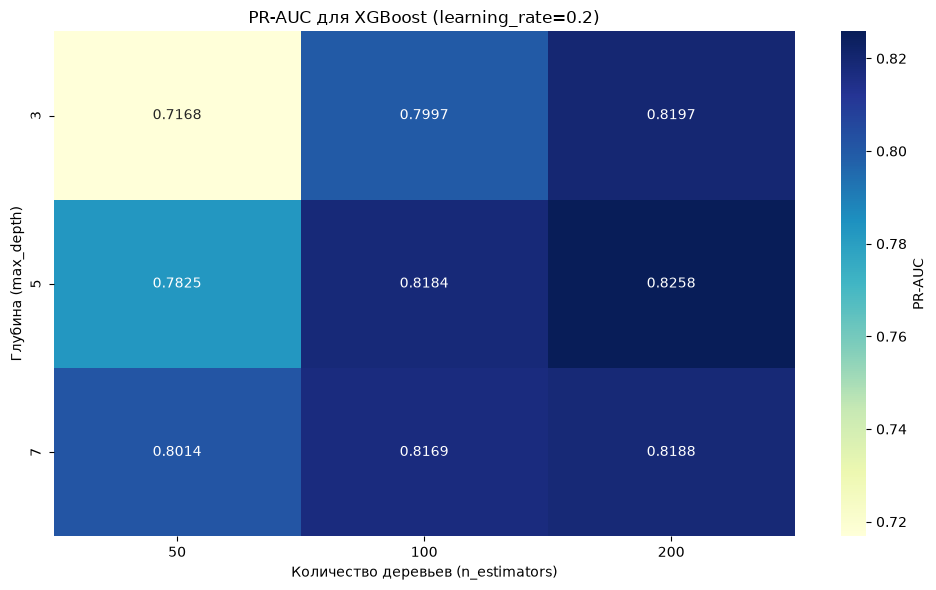

In [8]:
# Берем лучший learning_rate для графика
best_lr = df_scores_xgb_sorted.iloc[0]['learning_rate']
df_filtered = df_scores_xgb[df_scores_xgb['learning_rate'] == best_lr]

df_pivot = df_filtered.pivot(
    index='max_depth', 
    columns='n_estimators', 
    values='pr_auc'
)

plt.figure(figsize=(10, 6))
sns.heatmap(df_pivot, annot=True, fmt=".4f", cmap="YlGnBu", cbar_kws={'label': 'PR-AUC'})
plt.title(f'PR-AUC для XGBoost (learning_rate={best_lr})')
plt.xlabel('Количество деревьев (n_estimators)')
plt.ylabel('Глубина (max_depth)')
plt.tight_layout()
plt.show()

In [9]:
# Берем лучшие параметры
best_params_xgb = df_scores_xgb_sorted.iloc[0]
best_depth_xgb = int(best_params_xgb['max_depth'])
best_lr_xgb = float(best_params_xgb['learning_rate'])
best_n_xgb = int(best_params_xgb['n_estimators'])
print(f"Лучшие параметры: max_depth={best_depth_xgb}, learning_rate={best_lr_xgb}, n_estimators={best_n_xgb}")

# Обучаем на train
xgb_val = xgb.XGBClassifier(
    n_estimators=best_n_xgb, max_depth=best_depth_xgb, learning_rate=best_lr_xgb,
    scale_pos_weight=scale_weight, random_state=42, n_jobs=-1, eval_metric='logloss'
)
xgb_val.fit(X_train, y_train)
y_val_proba_xgb = xgb_val.predict_proba(X_val)[:, 1]

# Подбор порога
print(f"\n{'Threshold':<12} {'Precision':>10} {'Recall':>10} {'F1':>10}")
print("-" * 45)

best_threshold_xgb = 0
best_f1_xgb = 0

for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    y_val_pred = (y_val_proba_xgb >= t).astype(int)
    p = precision_score(y_val, y_val_pred, zero_division=0)
    r = recall_score(y_val, y_val_pred, zero_division=0)
    f = f1_score(y_val, y_val_pred, zero_division=0)
    
    print(f"{t:<12.1f} {p:>10.4f} {r:>10.4f} {f:>10.4f}")
    
    if f > best_f1_xgb:
        best_f1_xgb = f
        best_threshold_xgb = t

print(f"\nЛучший порог: {best_threshold_xgb} (F1 = {best_f1_xgb:.4f})")

Лучшие параметры: max_depth=5, learning_rate=0.2, n_estimators=200

Threshold     Precision     Recall         F1
---------------------------------------------
0.1              0.8495     0.7980     0.8229
0.2              0.8667     0.7879     0.8254
0.3              0.8851     0.7778     0.8280
0.4              0.8953     0.7778     0.8324
0.5              0.9259     0.7576     0.8333
0.6              0.9259     0.7576     0.8333
0.7              0.9259     0.7576     0.8333
0.8              0.9367     0.7475     0.8315
0.9              0.9487     0.7475     0.8362

Лучший порог: 0.9 (F1 = 0.8362)


In [10]:
# Обучаем на train+val
xgb_final = xgb.XGBClassifier(
    n_estimators=best_n_xgb, max_depth=best_depth_xgb, learning_rate=best_lr_xgb,
    scale_pos_weight=scale_weight, random_state=42, n_jobs=-1, eval_metric='logloss'
)
xgb_final.fit(X_train_full, y_train_full)

# Тест
y_test_proba_xgb = xgb_final.predict_proba(X_test)[:, 1]
y_test_pred_xgb = (y_test_proba_xgb >= best_threshold_xgb).astype(int)

print(f"=== XGBOOST (FINAL, threshold={best_threshold_xgb}) ===")
print(f"PR AUC   : {average_precision_score(y_test, y_test_proba_xgb):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred_xgb):.4f}")
print(f"Recall   : {recall_score(y_test, y_test_pred_xgb):.4f}")
print(f"F1       : {f1_score(y_test, y_test_pred_xgb):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_test_proba_xgb):.4f}")

=== XGBOOST (FINAL, threshold=0.9) ===
PR AUC   : 0.8729
Precision: 0.9091
Recall   : 0.8163
F1       : 0.8602
ROC AUC  : 0.9838


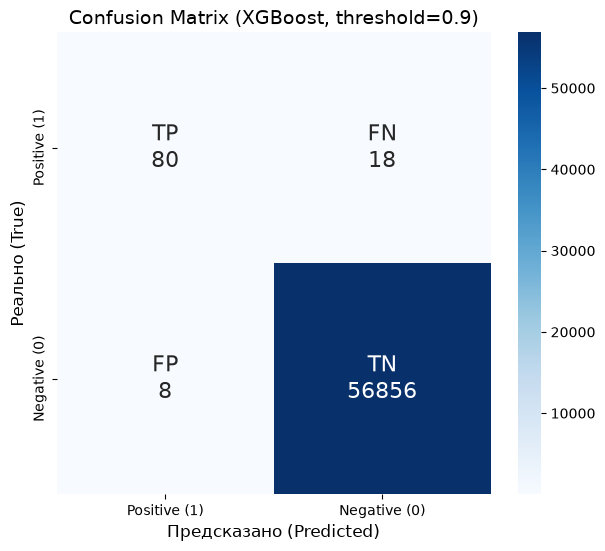

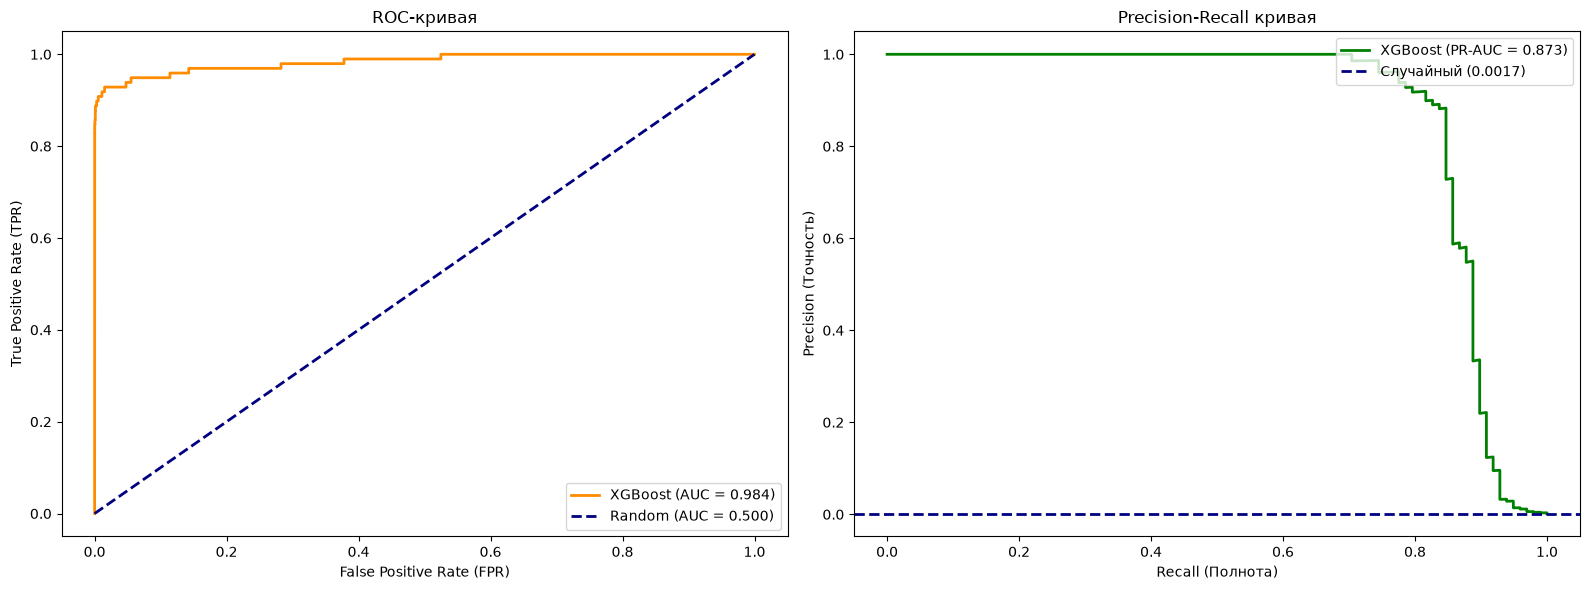

G:\TEMP\ipykernel_20100\1248448873.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=df_imp, palette='viridis')


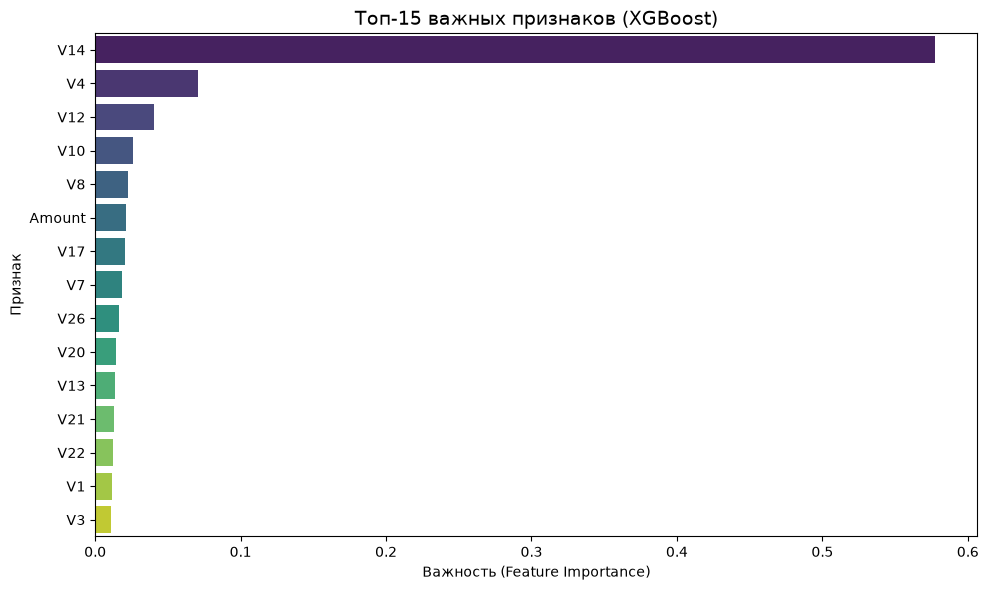


Топ-5 самых важных признаков:
feature  importance
    V14    0.577755
     V4    0.071012
    V12    0.040155
    V10    0.025990
     V8    0.022757


In [14]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve

# 1. МАТРИЦА ОШИБОК
# Строим матрицу (Scikit-learn порядок: [[TN, FP], [FN, TP]])
cm = confusion_matrix(y_test, y_test_pred_xgb)

# Переворачиваем, чтобы Positive (1) был сверху
cm_flipped = np.flip(cm)

# Подписи для ячеек
labels = np.array([
    [f'TP\n{cm[1, 1]}', f'FN\n{cm[1, 0]}'],
    [f'FP\n{cm[0, 1]}', f'TN\n{cm[0, 0]}']
])

plt.figure(figsize=(7, 6))
sns.heatmap(cm_flipped, annot=labels, fmt='', cmap='Blues',
            xticklabels=['Positive (1)', 'Negative (0)'],
            yticklabels=['Positive (1)', 'Negative (0)'],
            annot_kws={"size": 16})
plt.xlabel('Предсказано (Predicted)', fontsize=12)
plt.ylabel('Реально (True)', fontsize=12)
plt.title(f'Confusion Matrix (XGBoost, threshold={best_threshold_xgb})', fontsize=14)
plt.show()

# 2. ROC И PR-КРИВЫЕ
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

#  ROC Curve 
fpr, tpr, _ = roc_curve(y_test, y_test_proba_xgb)
roc_auc = auc(fpr, tpr)

axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'XGBoost (AUC = {roc_auc:.3f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random (AUC = 0.500)')
axes[0].set_xlabel('False Positive Rate (FPR)')
axes[0].set_ylabel('True Positive Rate (TPR)')
axes[0].set_title('ROC-кривая')
axes[0].legend(loc='lower right')

#  PR Curve 
precision, recall, _ = precision_recall_curve(y_test, y_test_proba_xgb)
pr_auc = average_precision_score(y_test, y_test_proba_xgb)
baseline = y_test.mean()

axes[1].plot(recall, precision, color='green', lw=2, label=f'XGBoost (PR-AUC = {pr_auc:.3f})')
axes[1].axhline(y=baseline, color='navy', lw=2, linestyle='--', label=f'Случайный ({baseline:.4f})')
axes[1].set_xlabel('Recall (Полнота)')
axes[1].set_ylabel('Precision (Точность)')
axes[1].set_title('Precision-Recall кривая')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

# 3. ВАЖНОСТЬ ПРИЗНАКОВ
# Получаем важность признаков из XGBoost
importances = xgb_final.feature_importances_
feature_names = X_train.columns.tolist()

# Создаем датафрейм и сортируем
df_imp = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values(by='importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=df_imp, palette='viridis')
plt.title('Топ-15 важных признаков (XGBoost)', fontsize=14)
plt.xlabel('Важность (Feature Importance)')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

print("\nТоп-5 самых важных признаков:")
print(df_imp.head(5).to_string(index=False))